This will be a more detailed implementation of the Black-Scholes Equation in European Options, taking into account other variables.

In [3]:
#Import dependencies
import yfinance as yf
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
from scipy.stats import norm
from fredapi import Fred
import creds

In [4]:
#Probability Density function; phi(d)
N = norm.cdf

#Define Call Option
def BlackSchole_Call(S, X, T, r, sigma):
    d1 = (np.log(S/X) + (r + (pow(sigma, 2) / 2)) * T) / (sigma * np.sqrt(T))
    d2 = d1 - (sigma * np.sqrt(T))

    return S*N(d1) - X*np.exp(-r*T)*N(d2)

#Define Put Option
def BlackSchole_Put(S, X, T, r, sigma):
    d1 = (np.log(S/X) + (r + (pow(sigma, 2) / 2)) * T) / (sigma * np.sqrt(T))
    d2 = d1 - (sigma * np.sqrt(T))
    return X*np.exp(-r*T)*N(-d2) - S*N(-d1)

Parameters:

The given parameters will be better calculated using other equations to derive the values.

Risk-Free Rate of Return: a theoretical concept that an investment that guarantees returns without any risks. (on paper)
Higher risk == higher chance for the investment to lose profit.

For risk-free investment to work:
1. you have to know your expected return with certainty
2. the entity making cash flow == NO default risk
3. No reinvestment risk

I will use data from FRED to calculate the Risk-Free Interest Rate of United Kingdom (Since we are looking at European model).

*Real Risk-Free Rate: Nominal Rate (e.g. 10-Year Bond Yield) - Expected Inflaton rate.*


In [5]:
#Test of FRED Api
#Importing data of UK Bond rates
fred = Fred(creds.api_key)

#10-year bond yields
UK_bond_yield = fred.get_series('IRLTLT01GBM156N')

#UK CPI YoY
UK_inflation = fred.get_series('CPALTT01GBM657N')

print("Latest UK 10-Year Bond Yield:")
print(UK_bond_yield.tail(1))

print("\nLatest UK YoY Inflation Rate (CPI):")
print(UK_inflation.tail(1))

#Calculate Risk-Free Rate
#Align dates
latest_date = min(UK_bond_yield.dropna().index[-1],
                  UK_inflation.dropna().index[-1])

rf_rate = UK_bond_yield.loc[latest_date] - UK_inflation[latest_date]
print(f"\nEstimated UK Real risk-free rate: {rf_rate:.2f}%")

Latest UK 10-Year Bond Yield:
2025-06-01    4.5248
dtype: float64

Latest UK YoY Inflation Rate (CPI):
2024-02-01    0.6
dtype: float64

Estimated UK Real risk-free rate: 3.52%


Implied Volatility:

Since it is difficult to compute the Implied Volatility as it does not have a closed-form solution, we will take into account for that and try to estimate its initial value using Brenner & Subrahmanyam's estimate from 1988:

$\sigma \approx \sqrt{\frac{2\pi}{T} \cdot \frac{C}{S}}$

Where:
- T: Total time to expiry
- C: price of option on the stock (call / put)
- S: stock price


In [9]:
#Initial Parameters
days = 30   #No. of historical Days to analyze
T_total = days / 365 #Total time to expiration (in years)

stock = yf.Ticker("SPY")
hist = stock.history(period=f'{days+5}d')
closing_prices = list(hist['Close'][-days:])

calls_df = stock.option_chain().calls
calls_df.head(10)

#Test for implied volatility
print("Implied volatility from latest trade: ")
iv_values = calls_df['impliedVolatility']
iv_values.head(1)   #Returns latest implied volatility rate

Implied volatility from latest trade: 


0    5.033207
Name: impliedVolatility, dtype: float64

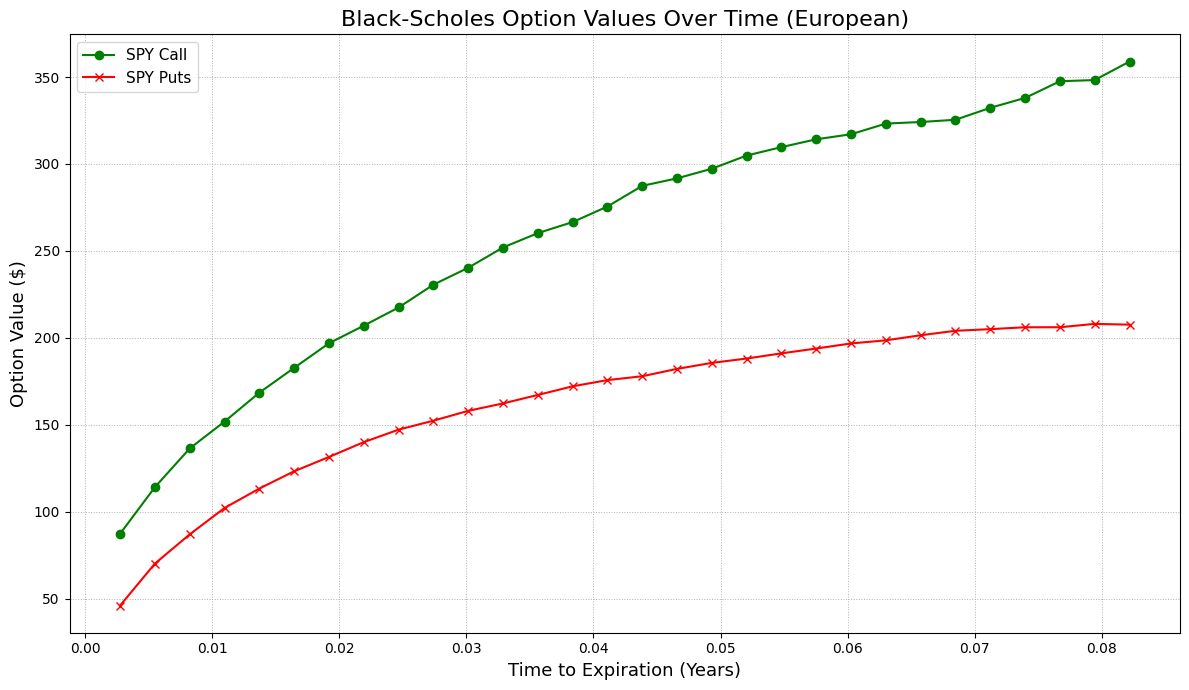

In [15]:
#Analytical Method

#Parameters
r = rf_rate #risk-free interest rate; Using estimation from above
sigma = iv_values.head(1) #Constant Implied volatility

#Redefine time period
days = 30
T_total = days / 365

#Plot figure
plt.figure(figsize=(12,7))

#Errors
if len(closing_prices) < days:
    print("Not enough data for {stock}. Skipping")

strike = closing_prices[0]

#Calculating Black_Scholes values
call_values = []
put_values = []
T_values = []

for i, prices in enumerate(closing_prices):
    T = T_total - (i/365)   #Days to expiry decreasing
    if T <= 0:
        continue
    call_values.append(BlackSchole_Call(prices, strike, T, r, sigma))
    put_values.append(BlackSchole_Put(prices, strike, T, r, sigma))
    T_values.append(T)

plt.plot(T_values, call_values, marker='o', color='green', label='SPY Call')
plt.plot(T_values, put_values, marker='x', color='red', label='SPY Puts')

plt.title('Black-Scholes Option Values Over Time (European)', fontsize=16)
plt.xlabel('Time to Expiration (Years)', fontsize=13)
plt.ylabel('Option Value ($)', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', linewidth=0.7)
plt.tight_layout()
plt.show()




In [21]:
#Calculating current prices:
print(BlackSchole_Call(prices, strike, T, r, sigma))
print(BlackSchole_Put(prices, strike, T, r, sigma))

#Calculating Intrinsic Prices
call_intrinsic = max(prices - strike, 0)
print(call_intrinsic)
put_intrinsic = max(strike-prices, 0)
print(put_intrinsic)

[87.36420046]
[46.05559347]
35.52630615234375
0


References:

*A Simple Formula to Compute the Implied Standard Deviaton; Menachem Brenner, Marti Subrahmanyam*
https://www.researchgate.net/publication/245065192_A_Simple_Formula_to_Compute_the_Implied_Standard_Deviation